# Lab 1: Elementary Sequences and Signal Variations
This notebook covers Tasks 1.1 and 1.2.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
import os

## Task 1.1 — Elementary Sequences
We generate and plot the Unit Impulse, Unit Step, Unit Ramp, and Real Exponential sequences.

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_594/2500180625.py:8: SyntaxWarning: invalid escape sequence '\d'
  for ax, x, title in zip(axes, [delta, step, ramp, expo], ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):


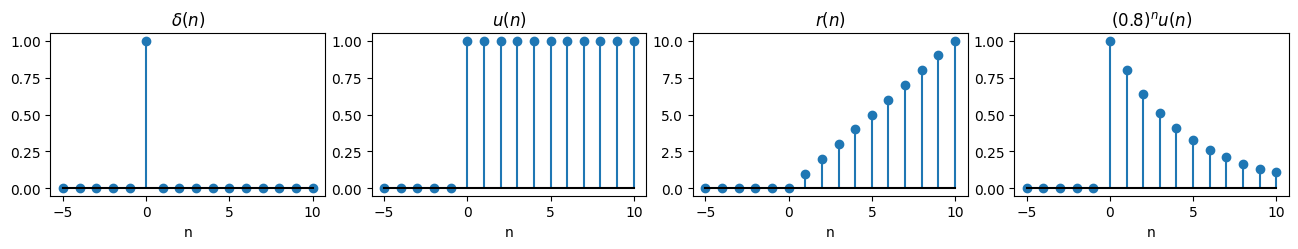

In [16]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # unit impulse
step  = (n >= 0).astype(float)       # unit step
ramp  = n * step                     # unit ramp
expo  = 0.8**n * step                # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo], ["$\delta(n)$", "$u(n)$", "$r(n)$", "$(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

## Task 1.2 — Parameter Variations

### 1. Plot $(a)^n u(n)$ for $a=0.5$, $a=-0.8$, and $a=1.1$

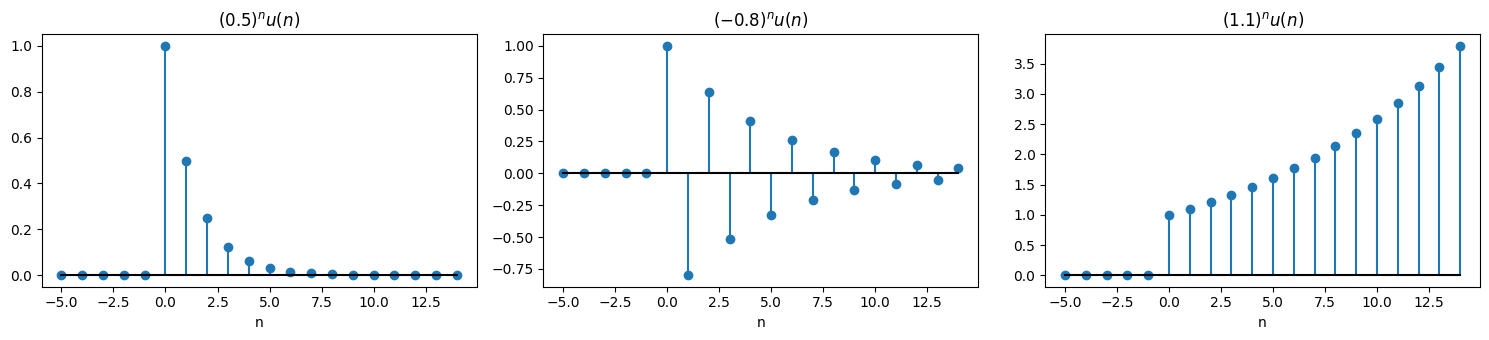

In [17]:
n_1_2 = np.arange(-5, 15)
step_1_2 = (n_1_2 >= 0).astype(float)

exp_1 = 0.5**n_1_2 * step_1_2
exp_2 = (-0.8)**n_1_2 * step_1_2
exp_3 = 1.1**n_1_2 * step_1_2

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

axes[0].stem(n_1_2, exp_1, basefmt="k-")
axes[0].set_title("$(0.5)^n u(n)$")
axes[0].set_xlabel("n")

axes[1].stem(n_1_2, exp_2, basefmt="k-")
axes[1].set_title("$(-0.8)^n u(n)$")
axes[1].set_xlabel("n")

axes[2].stem(n_1_2, exp_3, basefmt="k-")
axes[2].set_title("$(1.1)^n u(n)$")
axes[2].set_xlabel("n")

plt.tight_layout()
plt.show()

### 2. Plot $\cos(2\pi n / 8)$ and $\cos(2\pi n / 7.5)$ for $0 \le n \le 40$
We check which one repeats exactly.

<>:8: SyntaxWarning: invalid escape sequence '\c'
<>:13: SyntaxWarning: invalid escape sequence '\c'
<>:8: SyntaxWarning: invalid escape sequence '\c'
<>:13: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_594/70890225.py:8: SyntaxWarning: invalid escape sequence '\c'
  axes[0].set_title("$\cos(2\pi n / 8)$")
/tmp/ipykernel_594/70890225.py:13: SyntaxWarning: invalid escape sequence '\c'
  axes[1].set_title("$\cos(2\pi n / 7.5)$")


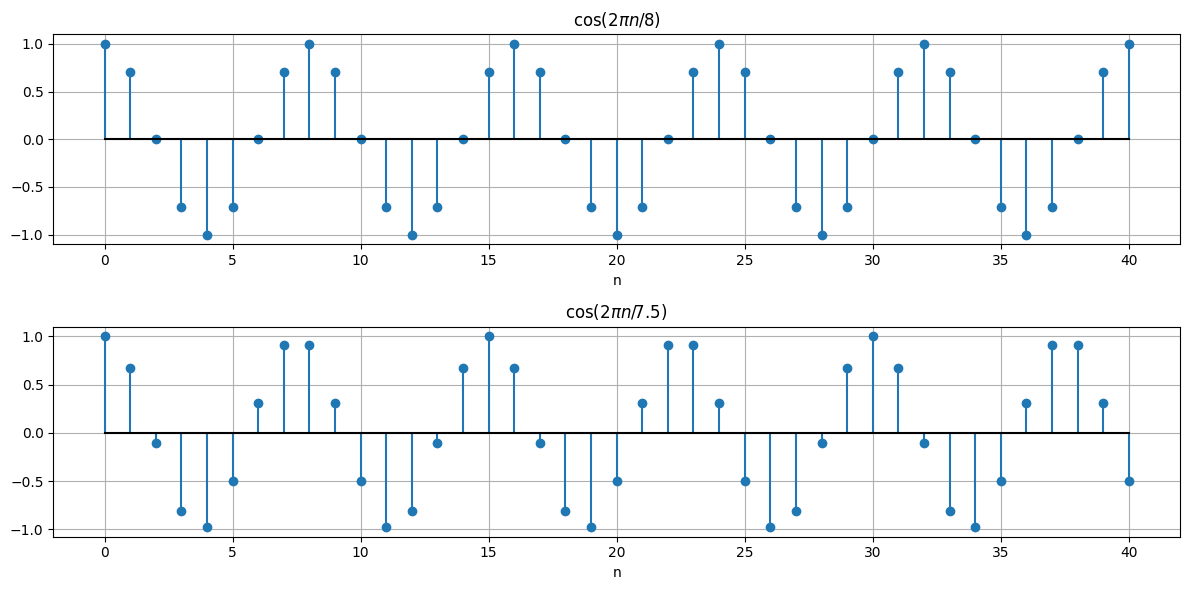

In [18]:
n_cos = np.arange(0, 41)
cos1 = np.cos(2 * np.pi * n_cos / 8)
cos2 = np.cos(2 * np.pi * n_cos / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].stem(n_cos, cos1, basefmt="k-")
axes[0].set_title("$\cos(2\pi n / 8)$")
axes[0].set_xlabel("n")
axes[0].grid(True)

axes[1].stem(n_cos, cos2, basefmt="k-")
axes[1].set_title("$\cos(2\pi n / 7.5)$")
axes[1].set_xlabel("n")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Task 1.3 — Working with Audio
We load a recording named `my_voice.wav` or generate a synthetic 440 Hz test tone as a fallback, plot the signal, and create an audio player.

fs = 44100 Hz, duration = 5.50 s, samples = 242727


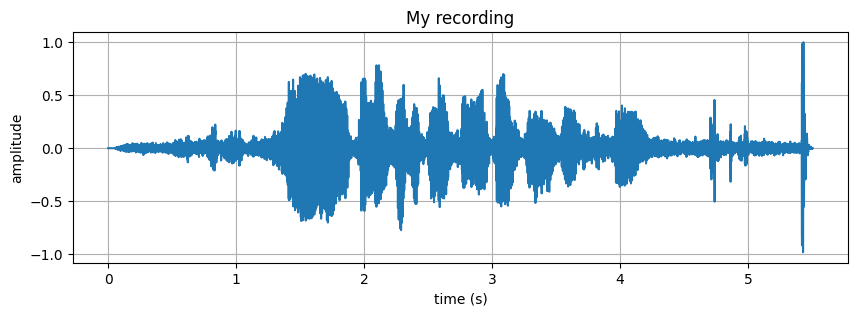

In [19]:
import os
from scipy.io import wavfile
from IPython.display import Audio

fname = "/content/myvoice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                          # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))               # normalise to [-1, 1]
else:                                       # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording" if os.path.exists(fname) else "Fallback Test Signal")
plt.grid(True)
plt.show()

In [20]:
Audio(x, rate=fs)

## Answers to Analysis Questions

### 1. Sampling rate of your phone's recording & numbers needed for one minute in mono
- **Sampling rate ($f_s$):** Typically $44100\text{ Hz}$ or $48000\text{ Hz}$ on most mobile devices.
- **Mono Storage for 1 minute:**
  $$\text{Samples} = f_s \times 60\text{ seconds}$$
  For $f_s = 44100\text{ Hz}$, this requires $44100 \times 60 = 2,646,000$ discrete numerical data points.

### 2. Why is a stem plot more appropriate than a continuous line for $x(n)$?
- $x(n)$ is a discrete-time sequence defined only at integer sample index values. A continuous line incorrectly suggests that values exist between samples, whereas a stem plot correctly depicts discrete sample impulses.

### 3. Which one of the cosines repeats exactly?
- $\cos(2\pi n / 8)$ repeats exactly with a fundamental period of $N = 8$ samples.
- $\cos(2\pi n / 7.5)$ also repeats exactly in discrete time because $7.5 = 15/2$ is a rational number ratio, resulting in a fundamental period of $N = 15$ samples.

### 4. Property violation for $a = 1.1$
- For $a = 1.1$, the exponential sequence $y(n) = (1.1)^n u(n)$ diverges towards infinity.
- If this signal were the impulse response $h(n)$ of a system, it would violate **BIBO stability** (Bounded-Input Bounded-Output stability) because the response is not absolutely summable:
  $$\sum_{n=-\infty}^{\infty} |h(n)| = \infty$$